# 4. Error analysis of the frozen Test comparison

## 1. Which examples are eligible, and what can inspection establish?

After Notebook 03's full comparison, inspect **exactly p1 at ranks 1, 5 and 10 for each of eight intents and both models**: 48 slots. No interesting-case replacement, label correction or new query is allowed. Repeated patches remain visible and counted. This deterministic diagnostic sample is neither random nor a frequency estimate over all results.

Computational categories describe satisfaction of the frozen **map reference**. They do not independently establish visual truth or model reasoning. Separate four layers: computed category; map uncertainty/generalization; qualitative RGB observation; possible explanation without an experiment. Native 10 m storage does not increase CLC2018's 25 ha/100 m mapping detail.

## 2. Configuration and verified saved artifacts

Only local saved results and pinned rasters are read; this notebook never invokes inference or acquisition.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display

from earth_observation.final_evaluation import load_final
from earth_observation.result_figures import (
    MODEL_NAMES,
    error_sample_figure,
    sample_conditions,
)

warnings.filterwarnings("ignore", message="IProgress not found.*")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULT_DIR = ROOT / "results/final-evaluation-v1"
result = load_final(ROOT)
notes = json.loads((RESULT_DIR / "qualitative-observations.json").read_text())
assert notes["result_content_sha256"] == result["content_sha256"]
samples = sample_conditions(ROOT, result)
assert len(samples) == 48
assert samples.patch_id.nunique() == 35
assert set(samples["rank"]) == {1, 5, 10}
assert samples.query_id.str.endswith("/p1").all()
print(f"48 fixed slots, {samples.patch_id.nunique()} unique images; labels unchanged")
display(samples.groupby(["model_id", "category"]).size().unstack(fill_value=0))
display(
    samples.groupby("patch_id")
    .size()
    .value_counts()
    .sort_index()
    .rename_axis("occurrences_per_image")
    .to_frame("unique_images")
)

48 fixed slots, 35 unique images; labels unchanged


category,class-a-only,class-b-only,neither,satisfied,single-presence-failure
model_id,,,,,
clip-openai-vit-b32,5,4,0,9,6
remoteclip-vit-b32,5,4,3,5,7


,unique_images
occurrences_per_image,
1,25
2,8
3,1
4,1


## 3. How should RGB and map evidence be read?

RGB uses the unchanged DN/3000 display scaling, without map-derived masks. Maps retain their native pixel grids and frozen class aggregation; known other classes are gray and unknown areas purple. Tables recompute native area bounds and summed four-neighbor contact, then check relevance against the saved frozen state. Presence needs ≥5% of the full 144 ha patch; adjacency additionally needs both presences and ≥60 m contact. No corner or off-patch contact counts.

All sampled states are known, although the full Test contains unknown judgments. Broad polygons can contain visually distinct parcels or small features; arable land versus pasture cannot be validated reliably from a single RGB image. Categories refer to these thresholded maps. For two-class intents, `class-a-only`/`class-b-only` follow query class order.

## 4. What do the fixed single-forest examples show?

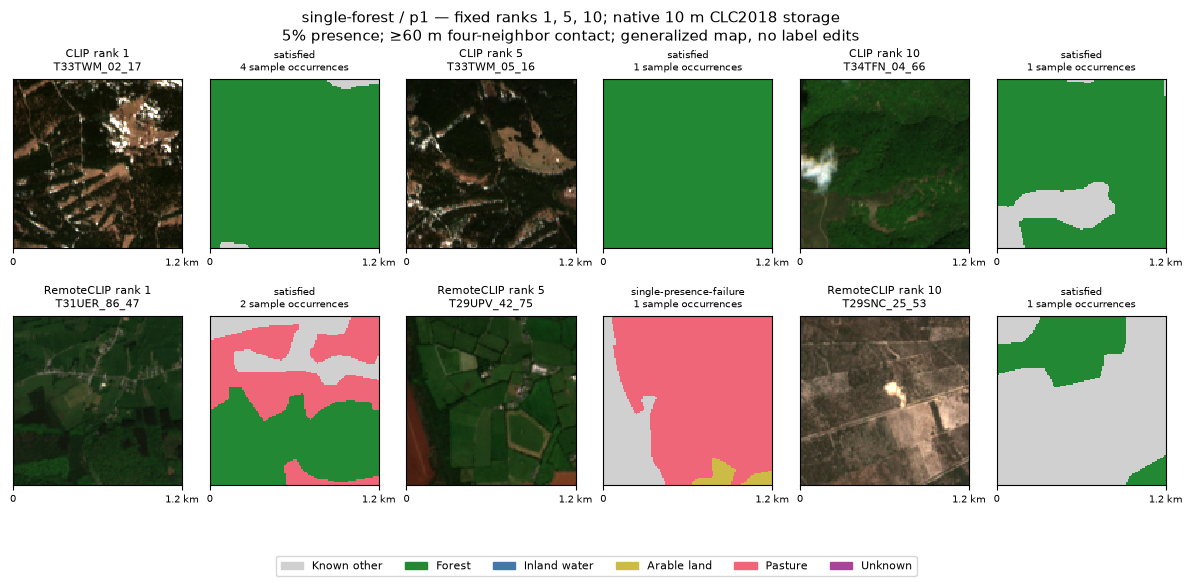

,model,rank,patch_id,category,presence_conditions,contact_lower_m,contact_upper_m,image_occurrences_in_48_slots
0,CLIP,1,S2B_MSIL2A_20180421T100029_N9999_R122_T33TWM_0...,satisfied,forest: 98.19–98.19% (true),NaN,NaN,4
1,CLIP,5,S2B_MSIL2A_20180421T100029_N9999_R122_T33TWM_0...,satisfied,forest: 100.00–100.00% (true),NaN,NaN,1
2,CLIP,10,S2B_MSIL2A_20180509T092029_N9999_R093_T34TFN_0...,satisfied,forest: 85.26–85.26% (true),NaN,NaN,1
3,RemoteCLIP,1,S2B_MSIL2A_20180506T105029_N9999_R051_T31UER_8...,satisfied,forest: 44.42–44.42% (true),NaN,NaN,2
4,RemoteCLIP,5,S2A_MSIL2A_20170717T113321_N9999_R080_T29UPV_4...,single-presence-failure,forest: 0.00–0.00% (false),NaN,NaN,1
5,RemoteCLIP,10,S2A_MSIL2A_20170813T112121_N9999_R037_T29SNC_2...,satisfied,forest: 24.48–24.48% (true),NaN,NaN,1


In [2]:
intent_id = "single-forest"
selected = samples[samples.intent_id.eq(intent_id)].copy()
fig = error_sample_figure(ROOT, samples, intent_id)
display(fig)
plt.close(fig)
selected["model"] = selected.model_id.map(MODEL_NAMES)
display(
    selected[
        [
            "model",
            "rank",
            "patch_id",
            "category",
            "presence_conditions",
            "contact_lower_m",
            "contact_upper_m",
            "image_occurrences_in_48_slots",
        ]
    ]
)

**Qualitative RGB observation:** CLIP selected scenes contain broad dark-green blocks with pale clearings; RemoteCLIP rank 5 is a field mosaic mapped without forest.

**Map limitation/generalization:** Uniform forest map regions encompass visible internal texture and clearings.

**Possible explanation, not experimentally demonstrated:** Canopy texture or broad landscape appearance may influence similarity; this sample does not test that mechanism.

The computational categories and numerical conditions are in the table; visual inspection has not changed them.

## 5. What do the fixed single-inland-water examples show?

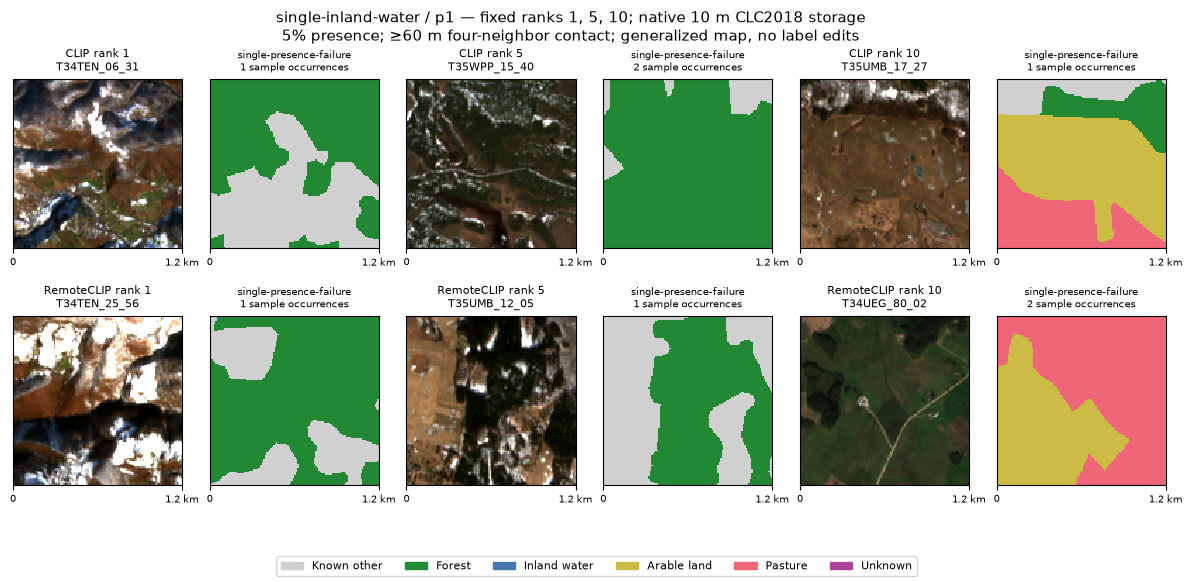

,model,rank,patch_id,category,presence_conditions,contact_lower_m,contact_upper_m,image_occurrences_in_48_slots
6,CLIP,1,S2A_MSIL2A_20171208T093351_N9999_R136_T34TEN_0...,single-presence-failure,inland_water: 0.00–0.00% (false),NaN,NaN,1
7,CLIP,5,S2A_MSIL2A_20180510T094031_N9999_R036_T35WPP_1...,single-presence-failure,inland_water: 0.00–0.00% (false),NaN,NaN,2
8,CLIP,10,S2A_MSIL2A_20180318T093031_N9999_R136_T35UMB_1...,single-presence-failure,inland_water: 0.00–0.00% (false),NaN,NaN,1
9,RemoteCLIP,1,S2A_MSIL2A_20171208T093351_N9999_R136_T34TEN_2...,single-presence-failure,inland_water: 0.00–0.00% (false),NaN,NaN,1
10,RemoteCLIP,5,S2A_MSIL2A_20180318T093031_N9999_R136_T35UMB_1...,single-presence-failure,inland_water: 0.00–0.00% (false),NaN,NaN,1
11,RemoteCLIP,10,S2B_MSIL2A_20170930T095019_N9999_R079_T34UEG_8...,single-presence-failure,inland_water: 0.00–0.00% (false),NaN,NaN,2


In [3]:
intent_id = "single-inland-water"
selected = samples[samples.intent_id.eq(intent_id)].copy()
fig = error_sample_figure(ROOT, samples, intent_id)
display(fig)
plt.close(fig)
selected["model"] = selected.model_id.map(MODEL_NAMES)
display(
    selected[
        [
            "model",
            "rank",
            "patch_id",
            "category",
            "presence_conditions",
            "contact_lower_m",
            "contact_upper_m",
            "image_occurrences_in_48_slots",
        ]
    ]
)

**Qualitative RGB observation:** Bright white patches and dark areas occur among the selected winter scenes. All six sampled slots have zero mapped inland-water area.

**Map limitation/generalization:** Small or seasonally obscured water cannot be validated from these RGB displays; zero mapped water is not proof of visually absent water.

**Possible explanation, not experimentally demonstrated:** Snow, shadow or scene appearance may affect the water rankings; no ablation or independent water annotation establishes the cause.

The computational categories and numerical conditions are in the table; visual inspection has not changed them.

## 6. What do the fixed single-arable-land examples show?

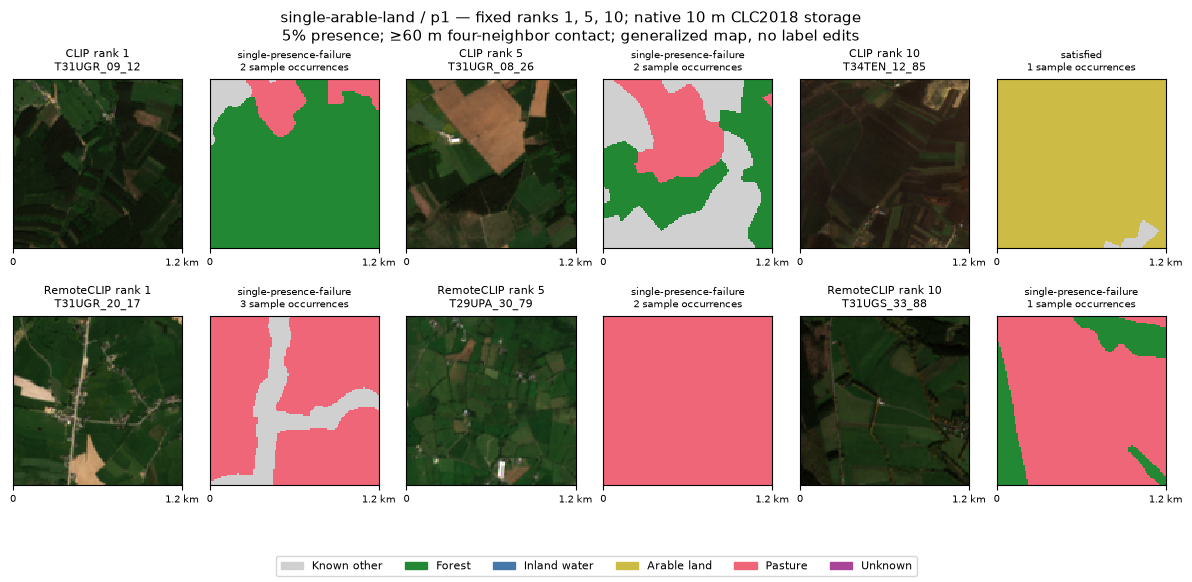

,model,rank,patch_id,category,presence_conditions,contact_lower_m,contact_upper_m,image_occurrences_in_48_slots
12,CLIP,1,S2A_MSIL2A_20180508T104031_N9999_R008_T31UGR_0...,single-presence-failure,arable_land: 0.00–0.00% (false),NaN,NaN,2
13,CLIP,5,S2A_MSIL2A_20180508T104031_N9999_R008_T31UGR_0...,single-presence-failure,arable_land: 0.00–0.00% (false),NaN,NaN,2
14,CLIP,10,S2A_MSIL2A_20171208T093351_N9999_R136_T34TEN_1...,satisfied,arable_land: 98.01–98.01% (true),NaN,NaN,1
15,RemoteCLIP,1,S2A_MSIL2A_20180508T104031_N9999_R008_T31UGR_2...,single-presence-failure,arable_land: 0.00–0.00% (false),NaN,NaN,3
16,RemoteCLIP,5,S2A_MSIL2A_20170717T113321_N9999_R080_T29UPA_3...,single-presence-failure,arable_land: 0.00–0.00% (false),NaN,NaN,2
17,RemoteCLIP,10,S2B_MSIL2A_20171015T104009_N9999_R008_T31UGS_3...,single-presence-failure,arable_land: 0.00–0.00% (false),NaN,NaN,1


In [4]:
intent_id = "single-arable-land"
selected = samples[samples.intent_id.eq(intent_id)].copy()
fig = error_sample_figure(ROOT, samples, intent_id)
display(fig)
plt.close(fig)
selected["model"] = selected.model_id.map(MODEL_NAMES)
display(
    selected[
        [
            "model",
            "rank",
            "patch_id",
            "category",
            "presence_conditions",
            "contact_lower_m",
            "contact_upper_m",
            "image_occurrences_in_48_slots",
        ]
    ]
)

**Qualitative RGB observation:** Rectangular fields, woodland blocks and built features are visible. CLIP rank 10 has a broad mapped arable region; the other five slots are map-negative.

**Map limitation/generalization:** Agricultural visual appearance alone does not identify arable land versus pasture; the coarse polygons differ from visible parcel edges.

**Possible explanation, not experimentally demonstrated:** Agricultural scene similarity may retrieve the wrong mapped agricultural class; crop identity is not independently verified.

The computational categories and numerical conditions are in the table; visual inspection has not changed them.

## 7. What do the fixed single-pasture examples show?

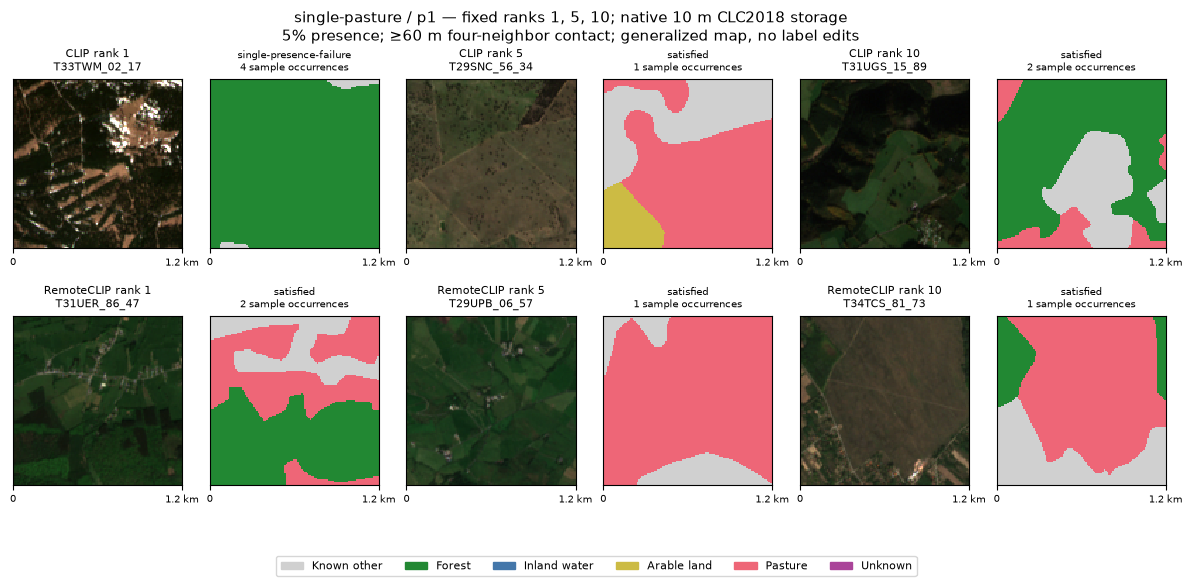

,model,rank,patch_id,category,presence_conditions,contact_lower_m,contact_upper_m,image_occurrences_in_48_slots
18,CLIP,1,S2B_MSIL2A_20180421T100029_N9999_R122_T33TWM_0...,single-presence-failure,pasture: 0.00–0.00% (false),NaN,NaN,4
19,CLIP,5,S2B_MSIL2A_20180224T112109_N9999_R037_T29SNC_5...,satisfied,pasture: 59.17–59.17% (true),NaN,NaN,1
20,CLIP,10,S2B_MSIL2A_20171015T104009_N9999_R008_T31UGS_1...,satisfied,pasture: 11.49–11.49% (true),NaN,NaN,2
21,RemoteCLIP,1,S2B_MSIL2A_20180506T105029_N9999_R051_T31UER_8...,satisfied,pasture: 37.07–37.07% (true),NaN,NaN,2
22,RemoteCLIP,5,S2B_MSIL2A_20170718T115359_N9999_R023_T29UPB_0...,satisfied,pasture: 85.49–85.49% (true),NaN,NaN,1
23,RemoteCLIP,10,S2A_MSIL2A_20171002T094031_N9999_R036_T34TCS_8...,satisfied,pasture: 65.23–65.23% (true),NaN,NaN,1


In [5]:
intent_id = "single-pasture"
selected = samples[samples.intent_id.eq(intent_id)].copy()
fig = error_sample_figure(ROOT, samples, intent_id)
display(fig)
plt.close(fig)
selected["model"] = selected.model_id.map(MODEL_NAMES)
display(
    selected[
        [
            "model",
            "rank",
            "patch_id",
            "category",
            "presence_conditions",
            "contact_lower_m",
            "contact_upper_m",
            "image_occurrences_in_48_slots",
        ]
    ]
)

**Qualitative RGB observation:** RemoteCLIP selected scenes show field mosaics and map-positive pasture. CLIP rank 1 repeats a largely wooded scene also selected for forest.

**Map limitation/generalization:** Mapped pasture areas are broad and do not follow every visible parcel boundary.

**Possible explanation, not experimentally demonstrated:** Shared vegetation/landscape cues may blur query distinctions; repetition is evidence of overlapping selected images, not a causal test.

The computational categories and numerical conditions are in the table; visual inspection has not changed them.

## 8. What do the fixed both-forest-water examples show?

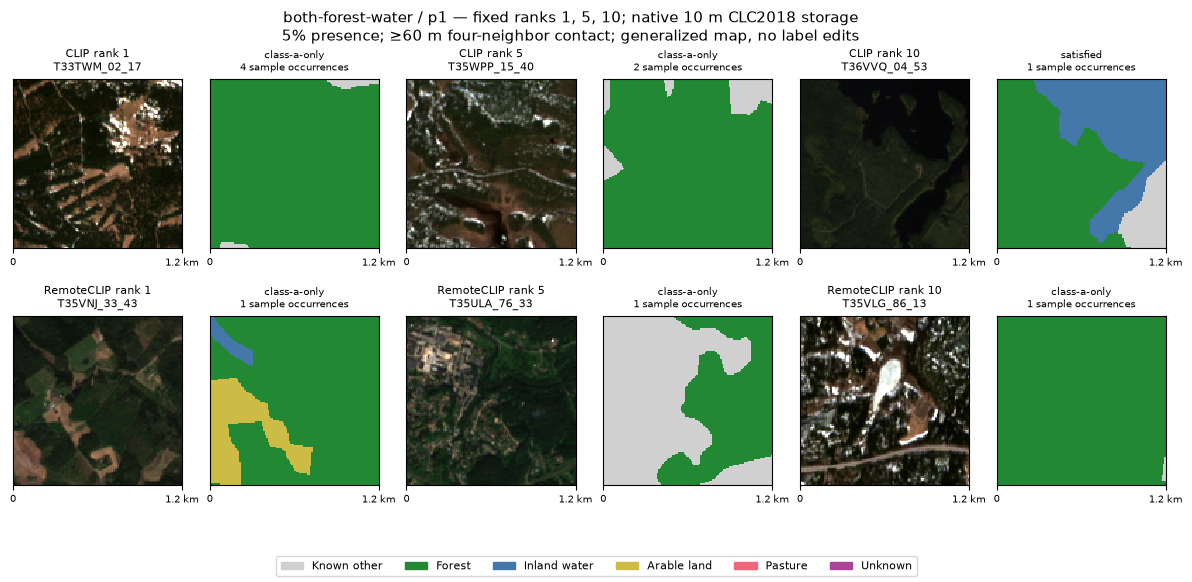

,model,rank,patch_id,category,presence_conditions,contact_lower_m,contact_upper_m,image_occurrences_in_48_slots
24,CLIP,1,S2B_MSIL2A_20180421T100029_N9999_R122_T33TWM_0...,class-a-only,forest: 98.19–98.19% (true); inland_water: 0.0...,NaN,NaN,4
25,CLIP,5,S2A_MSIL2A_20180510T094031_N9999_R036_T35WPP_1...,class-a-only,forest: 92.74–92.74% (true); inland_water: 0.0...,NaN,NaN,2
26,CLIP,10,S2B_MSIL2A_20170924T093019_N9999_R136_T36VVQ_0...,satisfied,forest: 56.37–56.37% (true); inland_water: 34....,NaN,NaN,1
27,RemoteCLIP,1,S2B_MSIL2A_20180515T094029_N9999_R036_T35VNJ_3...,class-a-only,forest: 80.22–80.22% (true); inland_water: 2.6...,NaN,NaN,1
28,RemoteCLIP,5,S2B_MSIL2A_20170808T094029_N9999_R036_T35ULA_7...,class-a-only,forest: 39.31–39.31% (true); inland_water: 0.0...,NaN,NaN,1
29,RemoteCLIP,10,S2A_MSIL2A_20180413T095031_N9999_R079_T35VLG_8...,class-a-only,forest: 99.77–99.77% (true); inland_water: 0.0...,NaN,NaN,1


In [6]:
intent_id = "both-forest-water"
selected = samples[samples.intent_id.eq(intent_id)].copy()
fig = error_sample_figure(ROOT, samples, intent_id)
display(fig)
plt.close(fig)
selected["model"] = selected.model_id.map(MODEL_NAMES)
display(
    selected[
        [
            "model",
            "rank",
            "patch_id",
            "category",
            "presence_conditions",
            "contact_lower_m",
            "contact_upper_m",
            "image_occurrences_in_48_slots",
        ]
    ]
)

**Qualitative RGB observation:** CLIP rank 10 shows a clear dark-water/vegetation division with mapped forest and water. The other slots contain woodland, fields, settlements or bright patches without both mapped presences.

**Map limitation/generalization:** RemoteCLIP rank 1 visibly contains a water-shaped feature, but its mapped water fraction remains below 5%; the frozen conjunction stays false.

**Possible explanation, not experimentally demonstrated:** Retrieving a salient partial condition may explain some results, but map generalization and the area threshold also constrain interpretation.

The computational categories and numerical conditions are in the table; visual inspection has not changed them.

## 9. What do the fixed adjacent-forest-water examples show?

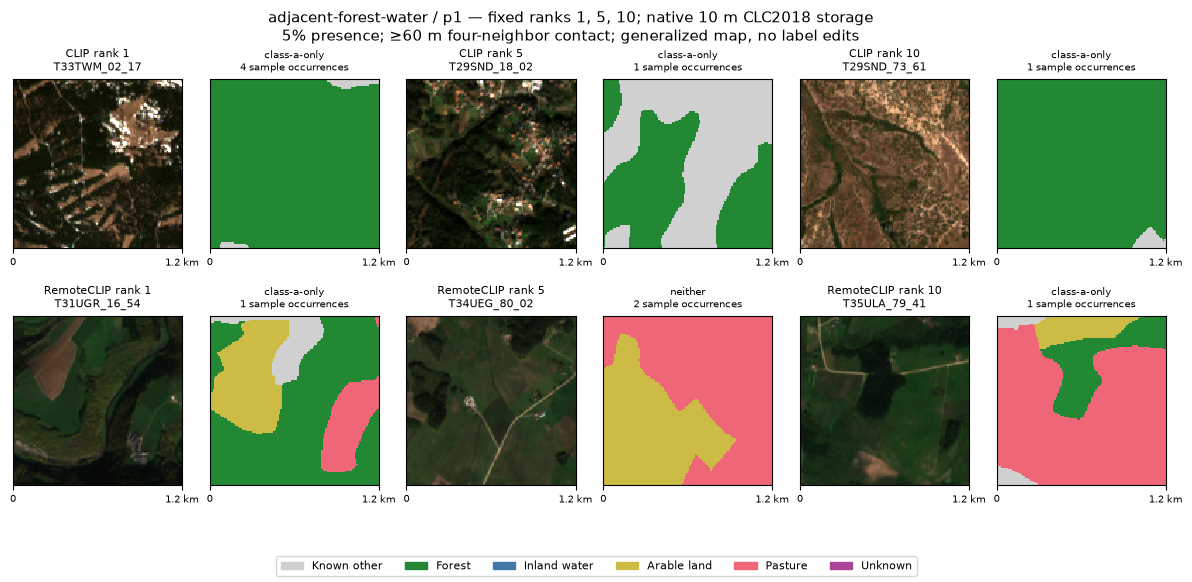

,model,rank,patch_id,category,presence_conditions,contact_lower_m,contact_upper_m,image_occurrences_in_48_slots
30,CLIP,1,S2B_MSIL2A_20180421T100029_N9999_R122_T33TWM_0...,class-a-only,forest: 98.19–98.19% (true); inland_water: 0.0...,0.0,0.0,4
31,CLIP,5,S2A_MSIL2A_20171221T112501_N9999_R037_T29SND_1...,class-a-only,forest: 45.68–45.68% (true); inland_water: 0.0...,0.0,0.0,1
32,CLIP,10,S2A_MSIL2A_20170704T112111_N9999_R037_T29SND_7...,class-a-only,forest: 98.49–98.49% (true); inland_water: 0.0...,0.0,0.0,1
33,RemoteCLIP,1,S2B_MSIL2A_20171015T104009_N9999_R008_T31UGR_1...,class-a-only,forest: 57.48–57.48% (true); inland_water: 0.0...,0.0,0.0,1
34,RemoteCLIP,5,S2B_MSIL2A_20170930T095019_N9999_R079_T34UEG_8...,neither,forest: 0.00–0.00% (false); inland_water: 0.00...,0.0,0.0,2
35,RemoteCLIP,10,S2B_MSIL2A_20170808T094029_N9999_R036_T35ULA_7...,class-a-only,forest: 15.74–15.74% (true); inland_water: 0.0...,0.0,0.0,1


In [7]:
intent_id = "adjacent-forest-water"
selected = samples[samples.intent_id.eq(intent_id)].copy()
fig = error_sample_figure(ROOT, samples, intent_id)
display(fig)
plt.close(fig)
selected["model"] = selected.model_id.map(MODEL_NAMES)
display(
    selected[
        [
            "model",
            "rank",
            "patch_id",
            "category",
            "presence_conditions",
            "contact_lower_m",
            "contact_upper_m",
            "image_occurrences_in_48_slots",
        ]
    ]
)

**Qualitative RGB observation:** The six selected scenes show wooded regions, fields and settlements; none passes both mapped presences.

**Map limitation/generalization:** The selected failures are presence failures, not isolated failures of mapped contact. Finer visible boundaries cannot validate the generalized relation.

**Possible explanation, not experimentally demonstrated:** Weak main adjacency quality may include failure to find both concepts; these slots cannot isolate spatial reasoning.

The computational categories and numerical conditions are in the table; visual inspection has not changed them.

## 10. What do the fixed both-arable-pasture examples show?

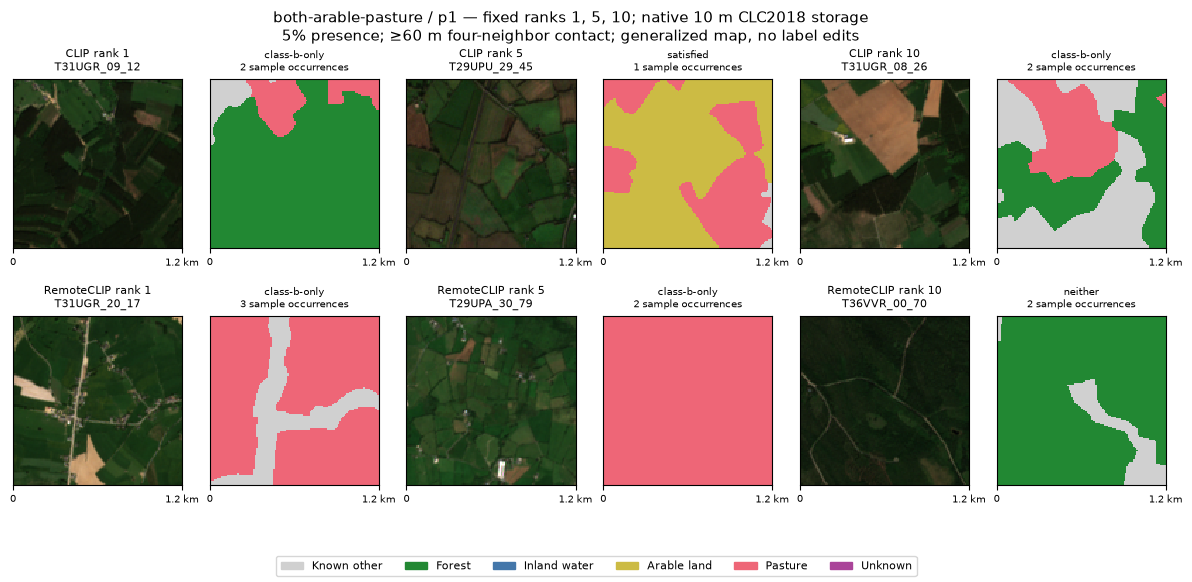

,model,rank,patch_id,category,presence_conditions,contact_lower_m,contact_upper_m,image_occurrences_in_48_slots
36,CLIP,1,S2A_MSIL2A_20180508T104031_N9999_R008_T31UGR_0...,class-b-only,arable_land: 0.00–0.00% (false); pasture: 11.2...,NaN,NaN,2
37,CLIP,5,S2B_MSIL2A_20171112T114339_N9999_R123_T29UPU_2...,satisfied,arable_land: 64.22–64.22% (true); pasture: 34....,NaN,NaN,1
38,CLIP,10,S2A_MSIL2A_20180508T104031_N9999_R008_T31UGR_0...,class-b-only,arable_land: 0.00–0.00% (false); pasture: 23.4...,NaN,NaN,2
39,RemoteCLIP,1,S2A_MSIL2A_20180508T104031_N9999_R008_T31UGR_2...,class-b-only,arable_land: 0.00–0.00% (false); pasture: 79.8...,NaN,NaN,3
40,RemoteCLIP,5,S2A_MSIL2A_20170717T113321_N9999_R080_T29UPA_3...,class-b-only,arable_land: 0.00–0.00% (false); pasture: 100....,NaN,NaN,2
41,RemoteCLIP,10,S2B_MSIL2A_20170716T093039_N9999_R136_T36VVR_0...,neither,arable_land: 0.00–0.00% (false); pasture: 0.00...,NaN,NaN,2


In [8]:
intent_id = "both-arable-pasture"
selected = samples[samples.intent_id.eq(intent_id)].copy()
fig = error_sample_figure(ROOT, samples, intent_id)
display(fig)
plt.close(fig)
selected["model"] = selected.model_id.map(MODEL_NAMES)
display(
    selected[
        [
            "model",
            "rank",
            "patch_id",
            "category",
            "presence_conditions",
            "contact_lower_m",
            "contact_upper_m",
            "image_occurrences_in_48_slots",
        ]
    ]
)

**Qualitative RGB observation:** CLIP rank 5 shows a field mosaic with both mapped agricultural classes. Other slots show field mosaics or a wooded scene without both mapped classes.

**Map limitation/generalization:** CLIP ranks 1 and 10 show visible fields but no mapped arable class. Single-date RGB does not independently establish land use.

**Possible explanation, not experimentally demonstrated:** Agricultural appearance without the specific conjunction is a possible explanation, not a verified model mechanism.

The computational categories and numerical conditions are in the table; visual inspection has not changed them.

## 11. What do the fixed adjacent-arable-pasture examples show?

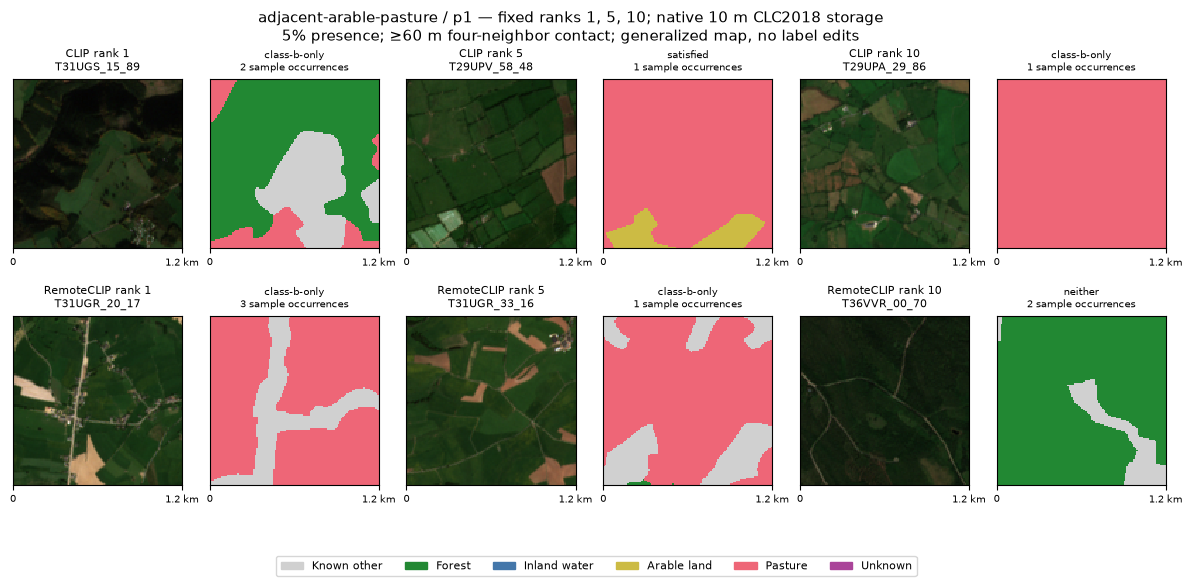

,model,rank,patch_id,category,presence_conditions,contact_lower_m,contact_upper_m,image_occurrences_in_48_slots
42,CLIP,1,S2B_MSIL2A_20171015T104009_N9999_R008_T31UGS_1...,class-b-only,arable_land: 0.00–0.00% (false); pasture: 11.4...,0.0,0.0,2
43,CLIP,5,S2A_MSIL2A_20170717T113321_N9999_R080_T29UPV_5...,satisfied,arable_land: 9.36–9.36% (true); pasture: 90.64...,2380.0,2380.0,1
44,CLIP,10,S2A_MSIL2A_20170717T113321_N9999_R080_T29UPA_2...,class-b-only,arable_land: 0.00–0.00% (false); pasture: 100....,0.0,0.0,1
45,RemoteCLIP,1,S2A_MSIL2A_20180508T104031_N9999_R008_T31UGR_2...,class-b-only,arable_land: 0.00–0.00% (false); pasture: 79.8...,0.0,0.0,3
46,RemoteCLIP,5,S2A_MSIL2A_20180508T104031_N9999_R008_T31UGR_3...,class-b-only,arable_land: 0.00–0.00% (false); pasture: 77.1...,0.0,0.0,1
47,RemoteCLIP,10,S2B_MSIL2A_20170716T093039_N9999_R136_T36VVR_0...,neither,arable_land: 0.00–0.00% (false); pasture: 0.00...,0.0,0.0,2


In [9]:
intent_id = "adjacent-arable-pasture"
selected = samples[samples.intent_id.eq(intent_id)].copy()
fig = error_sample_figure(ROOT, samples, intent_id)
display(fig)
plt.close(fig)
selected["model"] = selected.model_id.map(MODEL_NAMES)
display(
    selected[
        [
            "model",
            "rank",
            "patch_id",
            "category",
            "presence_conditions",
            "contact_lower_m",
            "contact_upper_m",
            "image_occurrences_in_48_slots",
        ]
    ]
)

**Qualitative RGB observation:** CLIP rank 5 shows fields and two mapped agricultural classes in contact. Other slots are map-negative; RemoteCLIP rank 10 repeats a wooded scene.

**Map limitation/generalization:** CLIP rank 5 has 9.36% arable and 90.64% pasture with 2,380 m mapped contact. The broad map regions do not resolve every parcel boundary.

**Possible explanation, not experimentally demonstrated:** Most sampled failures lack a mapped class; high scores need not indicate conjunction or relation satisfaction. This does not identify the mechanism.

The computational categories and numerical conditions are in the table; visual inspection has not changed them.

## 12. What does this sample explain, and what does it miss?

Among 24 slots per model, CLIP has 9 satisfied and 15 map-negative; RemoteCLIP has 5 satisfied and 19 negative. Both have nine partial-class failures across conjunction/relation queries; RemoteCLIP also has three neither-class cases. Across all 48 slots there are 35 unique images, so repeated results are not independent observations.

No selected slot has an unknown reference or a both-present-but-false relation. This limitation is reported rather than repaired by selecting different ranks. Many main relation-query failures already miss a presence condition; this sample cannot isolate relational discrimination. The separate full conditional controls in Notebook 03 contain the frozen two/seven hard negatives and remain exploratory.

Visible field patterns, snow/bright regions and internal map detail motivate possible explanations, not causal claims. Map categories are not corrected from RGB. Country-balanced sampling, scene prevalence, only two direct families and possible pretraining overlap further limit interpretation.

## 13. Saved evidence and the next decision

The exact slots/categories are in the versioned final summary; recomputed native conditions are saved below; `qualitative-observations.json` records the inspected fixed cases and separates observation, map limits and untested explanations. All scientific rules, labels and main candidates remain frozen. Human review of this final-evaluation PR precedes the separately authorized WP7 completion review.

In [10]:
samples.to_csv(RESULT_DIR / "error-sample-conditions.csv", index=False)
print("Saved 48 native-condition rows; no labels, queries or maps changed.")

Saved 48 native-condition rows; no labels, queries or maps changed.
